<a href="https://colab.research.google.com/github/JuanitaRozo/red-neuronal-siames/blob/main/Red_Neuronal_Siames.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==========================================
# PASO 1. IMPORTAR LIBRERÍAS
# ==========================================

import os
import zipfile
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from google.colab import files
from PIL import Image

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices('GPU'))

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

TensorFlow: 2.21.0
GPU disponible: []


In [ ]:
# ==========================================
# PASO 2. CARGAR DATASET FACIAL
# ==========================================

uploaded = files.upload()

ARCHIVO_ZIP = "dataset_faces.zip"
RUTA_DATASET = "/content/dataset_faces"

os.makedirs(RUTA_DATASET, exist_ok=True)

with zipfile.ZipFile(ARCHIVO_ZIP, 'r') as zip_ref:
    zip_ref.extractall(RUTA_DATASET)

print("Dataset descomprimido correctamente.")

Saving dataset_faces.zip to dataset_faces.zip
Dataset descomprimido correctamente.


In [ ]:
# ==========================================
# PASO 3. EXPLORAR DATASET
# ==========================================

EXTENSIONES = (".jpg", ".jpeg", ".png")

rutas_imagenes = []
etiquetas = []

for ruta in Path(RUTA_DATASET).rglob("*"):
    if ruta.is_file() and ruta.suffix.lower() in EXTENSIONES:

        # Identificar la carpeta de la persona
        carpeta_persona = next(
            (parte for parte in ruta.parts if parte.startswith("persona_")),
            ruta.parent.name
        )

        rutas_imagenes.append(str(ruta))
        etiquetas.append(carpeta_persona)

personas = sorted(set(etiquetas))

print("Personas encontradas:", personas)
print("Total de imágenes:", len(rutas_imagenes))

for persona in personas:
    cantidad = etiquetas.count(persona)
    print(persona, ":", cantidad, "imágenes")

assert len(personas) >= 2, "Se necesitan al menos dos identidades."
assert all(etiquetas.count(p) >= 2 for p in personas), \
    "Cada persona necesita al menos dos imágenes."

Personas encontradas: ['persona_01', 'persona_02', 'persona_03']
Total de imágenes: 9
persona_01 : 3 imágenes
persona_02 : 3 imágenes
persona_03 : 3 imágenes


In [ ]:
# ==========================================
# PASO 4. PREPROCESAMIENTO
# ==========================================

IMG_SIZE = (160, 160)

def cargar_imagen(ruta):

    imagen = Image.open(ruta).convert("RGB")

    imagen = imagen.resize(
        IMG_SIZE,
        Image.Resampling.LANCZOS
    )

    imagen = np.array(imagen, dtype=np.float32) / 255.0

    return imagen


X = np.array([
    cargar_imagen(ruta)
    for ruta in rutas_imagenes
], dtype=np.float32)

y = np.array(etiquetas)

print("Dimensiones del dataset:", X.shape)
print("Dimensiones de las etiquetas:", y.shape)
print("Valor mínimo:", X.min())
print("Valor máximo:", X.max())

Dimensiones del dataset: (9, 160, 160, 3)
Dimensiones de las etiquetas: (9,)
Valor mínimo: 0.0
Valor máximo: 1.0


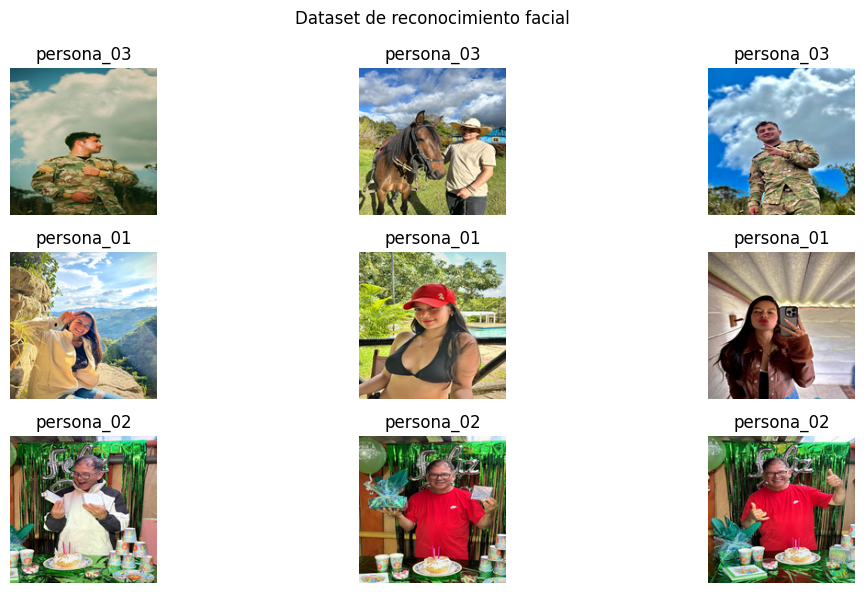

In [ ]:
# ==========================================
# PASO 5. VISUALIZAR DATASET
# ==========================================

plt.figure(figsize=(12, 6))

for i in range(len(X)):

    plt.subplot(3, 3, i + 1)
    plt.imshow(X[i])
    plt.title(y[i])
    plt.axis("off")

plt.suptitle("Dataset de reconocimiento facial")
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# PASO 6. ARQUITECTURA CNN
# ==========================================

from tensorflow.keras import layers, Model

def crear_encoder():

    entrada = layers.Input(
        shape=(160, 160, 3),
        name="imagen_rostro"
    )

    x = layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    )(entrada)

    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    )(x)

    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.Conv2D(
        128, (3, 3),
        activation="relu",
        padding="same"
    )(x)

    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(128, activation="relu")(x)

    salida = layers.Dense(64)(x)

    salida = layers.UnitNormalization(
        axis=1,
        name="embedding_normalizado"
    )(salida)

    return Model(
        entrada,
        salida,
        name="Encoder_Facial"
    )


encoder = crear_encoder()

encoder.summary()

Model: "Encoder_Facial"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen_rostro (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_normalizado           │ (None, 64)             │             0 │
│ (UnitNormalization)             │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118,016 (461.00 KB)

 Trainable params: 118,016 (461.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ==========================================
# PASO 7. FUNCIÓN TRIPLET LOSS
# ==========================================

MARGIN = 0.2

def triplet_loss(anchor, positive, negative):

    distancia_positiva = tf.reduce_sum(
        tf.square(anchor - positive),
        axis=1
    )

    distancia_negativa = tf.reduce_sum(
        tf.square(anchor - negative),
        axis=1
    )

    perdida = tf.maximum(
        distancia_positiva - distancia_negativa + MARGIN,
        0.0
    )

    return tf.reduce_mean(perdida)


print("Función Triplet Loss implementada correctamente.")

Función Triplet Loss implementada correctamente.


In [ ]:
# ==========================================
# PASO 8. GENERAR TRIPLETAS
# ==========================================

tripletas = []

for i in range(len(X)):

    identidad_anchor = y[i]

    positivos = [
        j for j in range(len(X))
        if y[j] == identidad_anchor and j != i
    ]

    negativos = [
        j for j in range(len(X))
        if y[j] != identidad_anchor
    ]

    for positivo in positivos:

        for negativo in negativos:

            tripletas.append((i, positivo, negativo))


tripletas = np.array(tripletas, dtype=np.int32)

np.random.shuffle(tripletas)

print("Total de tripletas:", len(tripletas))
print("Ejemplo de tripleta:", tripletas[0])

Total de tripletas: 108
Ejemplo de tripleta: [6 7 5]


In [ ]:
# ==========================================
# PASO 9. ENTRENAMIENTO
# ==========================================

EPOCHS = 20
BATCH_SIZE = 8
LEARNING_RATE = 0.001

optimizador = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)

historial_perdida = []

for epoch in range(EPOCHS):

    np.random.shuffle(tripletas)

    perdidas_epoch = []

    for inicio in range(0, len(tripletas), BATCH_SIZE):

        lote = tripletas[inicio:inicio + BATCH_SIZE]

        indices_a = lote[:, 0]
        indices_p = lote[:, 1]
        indices_n = lote[:, 2]

        anchor = tf.convert_to_tensor(X[indices_a])
        positive = tf.convert_to_tensor(X[indices_p])
        negative = tf.convert_to_tensor(X[indices_n])

        with tf.GradientTape() as tape:

            emb_anchor = encoder(anchor, training=True)
            emb_positive = encoder(positive, training=True)
            emb_negative = encoder(negative, training=True)

            perdida = triplet_loss(
                emb_anchor,
                emb_positive,
                emb_negative
            )

        gradientes = tape.gradient(
            perdida,
            encoder.trainable_variables
        )

        optimizador.apply_gradients(
            zip(gradientes, encoder.trainable_variables)
        )

        perdidas_epoch.append(float(perdida.numpy()))

    perdida_promedio = np.mean(perdidas_epoch)

    historial_perdida.append(perdida_promedio)

    print(
        f"Época {epoch + 1}/{EPOCHS} "
        f"- Triplet Loss: {perdida_promedio:.6f}"
    )

print("Entrenamiento finalizado.")

Época 1/20 - Triplet Loss: 0.077267
Época 2/20 - Triplet Loss: 0.054630
Época 3/20 - Triplet Loss: 0.065904
Época 4/20 - Triplet Loss: 0.061051
Época 5/20 - Triplet Loss: 0.028783
Época 6/20 - Triplet Loss: 0.066591
Época 7/20 - Triplet Loss: 0.074750
Época 8/20 - Triplet Loss: 0.097952
Época 9/20 - Triplet Loss: 0.044820
Época 10/20 - Triplet Loss: 0.023614
Época 11/20 - Triplet Loss: 0.005155
Época 12/20 - Triplet Loss: 0.003282
Época 13/20 - Triplet Loss: 0.053746
Época 14/20 - Triplet Loss: 0.007075
Época 15/20 - Triplet Loss: 0.008200
Época 16/20 - Triplet Loss: 0.010984
Época 17/20 - Triplet Loss: 0.000000
Época 18/20 - Triplet Loss: 0.000281
Época 19/20 - Triplet Loss: 0.000247
Época 20/20 - Triplet Loss: 0.000000
Entrenamiento finalizado.


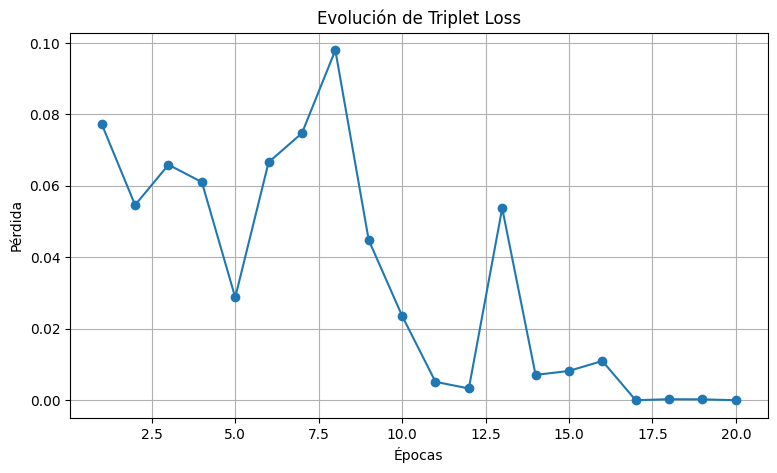

In [ ]:
# ==========================================
# PASO 10. RESULTADOS DEL ENTRENAMIENTO
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, EPOCHS + 1),
    historial_perdida,
    marker="o"
)

plt.title("Evolución de Triplet Loss")
plt.xlabel("Épocas")
plt.ylabel("Pérdida")
plt.grid(True)

plt.show()

In [ ]:
# ==========================================
# PASO 11. GENERAR EMBEDDINGS
# ==========================================

embeddings = encoder.predict(X, verbose=0)

print("Dimensiones de los embeddings:", embeddings.shape)

for i in range(len(embeddings)):
    print(
        f"{y[i]} - Embedding:",
        embeddings[i][:5]
    )

Dimensiones de los embeddings: (9, 64)
persona_03 - Embedding: [-0.05313141 -0.04438307 -0.1120678  -0.01454381  0.19625708]
persona_03 - Embedding: [-0.05389502 -0.04209793 -0.11849604 -0.0171551   0.20112227]
persona_03 - Embedding: [-0.07096391 -0.02866258 -0.12220972 -0.01523096  0.1920626 ]
persona_01 - Embedding: [ 0.17804986 -0.19946948 -0.038469   -0.0520139   0.20524682]
persona_01 - Embedding: [ 0.12764123 -0.17297953 -0.05769361 -0.04593932  0.21555527]
persona_01 - Embedding: [ 0.1798009  -0.20027812 -0.02776865 -0.05483182  0.19371872]
persona_02 - Embedding: [-0.22447178  0.15989439 -0.11056086  0.02769093  0.02050112]
persona_02 - Embedding: [-0.21802507  0.15666686 -0.08036217  0.04400516  0.00094266]
persona_02 - Embedding: [-0.22416706  0.1685395  -0.08765142  0.03731795 -0.00523424]


Identidad imagen 1: persona_03
Identidad imagen 2: persona_03
Distancia euclidiana: 0.0337


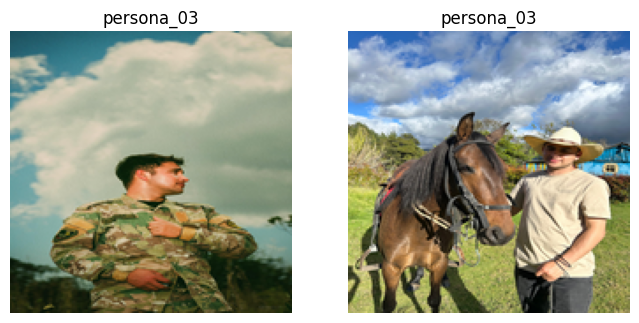

In [ ]:
# ==========================================
# PASO 12. COMPARACIÓN DE ROSTROS
# ==========================================

def comparar_rostros(indice_1, indice_2):

    embedding_1 = embeddings[indice_1]
    embedding_2 = embeddings[indice_2]

    distancia = np.linalg.norm(
        embedding_1 - embedding_2
    )

    print("Identidad imagen 1:", y[indice_1])
    print("Identidad imagen 2:", y[indice_2])
    print("Distancia euclidiana:", round(float(distancia), 4))

    plt.figure(figsize=(8, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(X[indice_1])
    plt.title(str(y[indice_1]))
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(X[indice_2])
    plt.title(str(y[indice_2]))
    plt.axis("off")

    plt.show()

    return float(distancia)


# Comparar dos fotografías de la misma persona
distancia = comparar_rostros(0, 1)

In [16]:
# Comparación adicional: persona_01 vs persona_02
distancia = np.linalg.norm(embeddings[3] - embeddings[6])

print("Identidad imagen 1:", y[3])
print("Identidad imagen 2:", y[6])
print("Distancia euclidiana:", round(float(distancia), 4))

if distancia < UMBRAL:
    print("Resultado: MISMA IDENTIDAD")
else:
    print("Resultado: IDENTIDAD DIFERENTE")

Identidad imagen 1: persona_01
Identidad imagen 2: persona_02
Distancia euclidiana: 1.6253
Resultado: IDENTIDAD DIFERENTE


In [ ]:
# ==========================================
# PASO 13. VERIFICACIÓN FACIAL
# ==========================================

UMBRAL = 0.7

def verificar_identidad(indice_1, indice_2):

    distancia = np.linalg.norm(
        embeddings[indice_1] - embeddings[indice_2]
    )

    if distancia < UMBRAL:
        resultado = "MISMA IDENTIDAD"
    else:
        resultado = "IDENTIDAD DIFERENTE"

    print("Distancia:", round(float(distancia), 4))
    print("Resultado:", resultado)

    return resultado


verificar_identidad(0, 1)
verificar_identidad(0, 3)

Distancia: 0.0337
Resultado: MISMA IDENTIDAD
Distancia: 0.9263
Resultado: IDENTIDAD DIFERENTE


'IDENTIDAD DIFERENTE'

In [ ]:
# ==========================================
# PASO 14. GUARDAR MODELO
# ==========================================

encoder.save("/content/modelo_reconocimiento_facial.keras")

print("Modelo guardado correctamente.")

files.download(
    "/content/modelo_reconocimiento_facial.keras"
)

Modelo guardado correctamente.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>